In [1]:
from run_experiment import run_experiment_single_class, build_dataloaders, build_model
from utils.visualization import visualize_anomalies
from utils.helpers import set_seed, get_device
from utils.data_split import split_data
from losses import MSELoss
import pandas as pd

W1107 17:17:47.547000 24160 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


In [ ]:
config = {

    'experiment_name': 'prova',

    'device': 'cuda',
    'num_workers': 0,
    'seed': 42,

    # dataset
    'img_size': (256, 256),
    'batch_size': 16,

    # training
    'loss_fn': MSELoss,
    'learning_rate': 1e-3,
    'patience': 5,

    # model
    'model_name': 'Autoencoder',
    'base_channels': 16,
    'num_epochs': 10,
    'output_dir': './experiments/pixel_reconstruction',
    'class_name': 'bottle',  # Specify the class name for training and evaluation
}

In [3]:
set_seed(config['seed'])
DEVICE = get_device(config['device'])
print(f"Using device: {DEVICE}")

Random seed set to 42.
Using device: cuda


### Train-Validation split
The MVTec AD dataset does not provide an official validation set. Therefore, a validation set is created by partitioning the original training set, which contains only defect-free (normal) images. The resulting validation set is used to monitor overfitting and implement early stopping. The test set is kept separate and used exclusively for final evaluation.

In [4]:
do_split = False  # Set to True if you want to split the dataset into training and validation sets
if do_split:
    # Split a single class
    #split_data(root="./data/MVTec", class_name="bottle", val_ratio=0.15)

    # Or split all classes under data/MVTec at once:
    split_data(root="./data/MVTec", val_ratio=0.15)

### Model Training and Evaluation

In [ ]:
# history, metrics = run_experiment_single_class('bottle', config)

# print("Training and evaluation completed.")
# print("Metrics:", metrics)



==============================  Starting class: BOTTLE  ==============================
Training Autoencoder for class 'bottle' on device: cuda


Epoch [001/002] | Train Loss: 0.06429 | Val Loss: 0.11887


Epoch [002/002] | Train Loss: 0.01605 | Val Loss: 0.01964


Training and evaluation completed.
Metrics: {'image_auroc': 0.4166666865348816, 'pixel_auroc': 0.4262844920158386, 'aupro': 0.21281753480434418}


In [6]:
classes_to_run = ['bottle', 'cable', 'wood']
all_results = {}

for cls in classes_to_run:
    history, metrics = run_experiment_single_class(cls, config)
    all_results[cls] = metrics


==============================  Starting class: BOTTLE  ==============================
Training Autoencoder for class 'bottle' on device: cuda


Train:   0%|          | 0/12 [00:00<?, ?it/s]

Epoch [001/002] | Train Loss: 0.06642 | Val Loss: 0.09395


Epoch [002/002] | Train Loss: 0.01467 | Val Loss: 0.02327



==============================  Starting class: CABLE  ==============================
Training Autoencoder for class 'cable' on device: cuda


Epoch [001/002] | Train Loss: 0.02896 | Val Loss: 0.04416


Epoch [002/002] | Train Loss: 0.01093 | Val Loss: 0.02734



==============================  Starting class: WOOD  ==============================
Training Autoencoder for class 'wood' on device: cuda


Epoch [001/002] | Train Loss: 0.00749 | Val Loss: 0.00718


Epoch [002/002] | Train Loss: 0.00253 | Val Loss: 0.00374


In [7]:
df_results = pd.DataFrame.from_dict(all_results, orient='index')
df_results.loc['MEAN'] = df_results.mean()

# results_csv = Path(config['exp_root']) / "benchmark_results.csv"
# df_results.to_csv(results_csv)

display(df_results.round(4))

,image_auroc,pixel_auroc,aupro
bottle,0.4183,0.4501,0.1899
cable,0.5369,0.7799,0.4879
wood,0.9412,0.7234,0.6170
MEAN,0.6321,0.6511,0.4316


Loaded model weights from experiments/pixel_reconstruction/prova/wood/checkpoints/best_model.pth


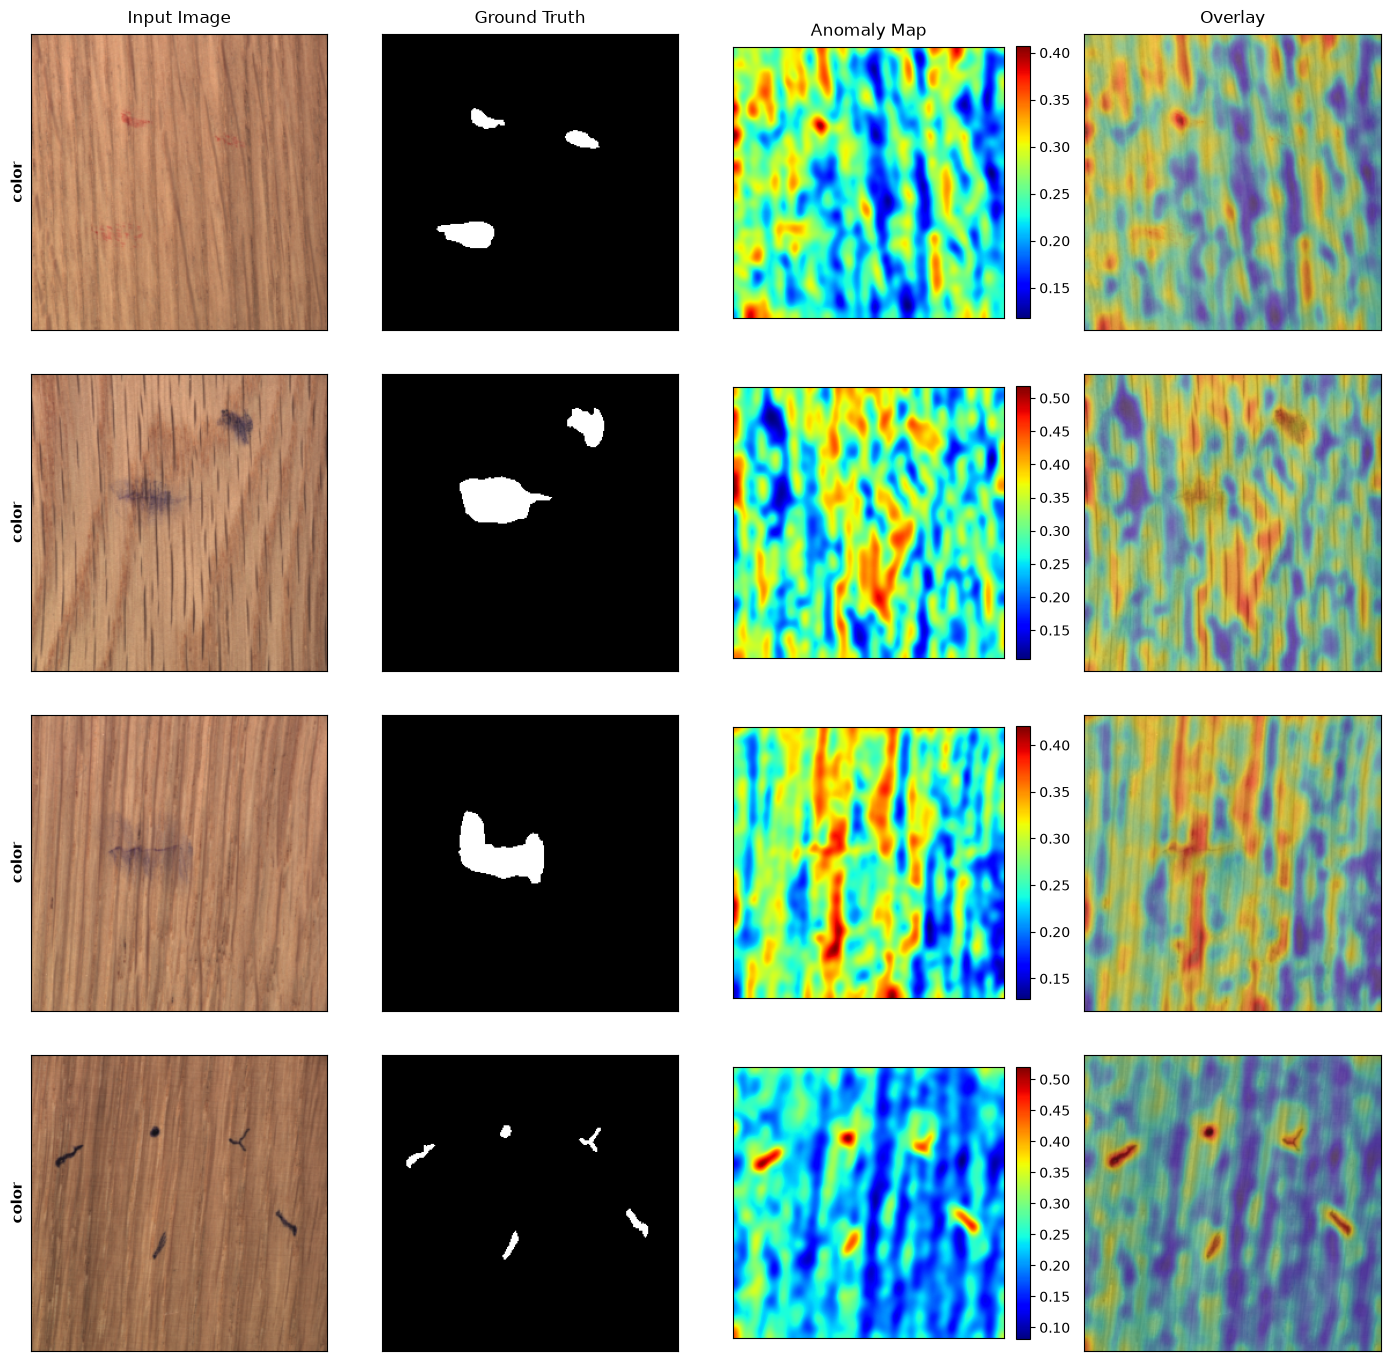

In [11]:
object_name = "wood"  # Change this to the desired object name
checkpoint_path = f"experiments/pixel_reconstruction/{config['experiment_name']}/{object_name}/checkpoints/best_model.pth"

_, _, test_loader = build_dataloaders(object_name, config)
model = build_model(config, DEVICE, checkpoint_path=checkpoint_path)
visualize_anomalies(model, test_loader, DEVICE)